In [16]:
import json
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
train_datafile, test_datafile, val_datafile = "data/100k/train.csv", "data/100k/val.csv", "data/100k/test.csv"

# "attributes": {
#         "weather": "clear",
#         "scene": "city street",
#         "timeofday": "dawn/dusk"
#     }

In [51]:
df = pd.read_csv(val_datafile) 
label_files = df["labels"].tolist()
num_images = 0
weather_count = Counter()
scene_count = Counter()
timeofday_count = Counter()
category_count = Counter()

for file in label_files:
    with open(file, "r") as f:
        data = json.load(f)

        # image attributes
        weather_count[data["attributes"]["weather"]] += 1
        scene_count[data["attributes"]["scene"]] += 1
        timeofday_count[data["attributes"]["timeofday"]] += 1

        # process objects within the frame
        for frame in data["frames"]:
            num_images += 1
            for object in frame["objects"]:
                category_count[object["category"]] += 1
            

In [ ]:
print(num_images)
print(category_count)
print(len(category_count))

40000
Counter({'car': 410300, 'lane/single white': 141548, 'traffic sign': 138012, 'traffic light': 105680, 'lane/road curb': 63434, 'lane/crosswalk': 61204, 'person': 49300, 'area/drivable': 36856, 'area/alternative': 35492, 'lane/double yellow': 21008, 'truck': 17408, 'lane/single yellow': 11850, 'bus': 6434, 'bike': 3996, 'lane/double white': 3402, 'rider': 2588, 'motor': 1682, 'lane/single other': 210, 'train': 56, 'lane/double other': 20})
20


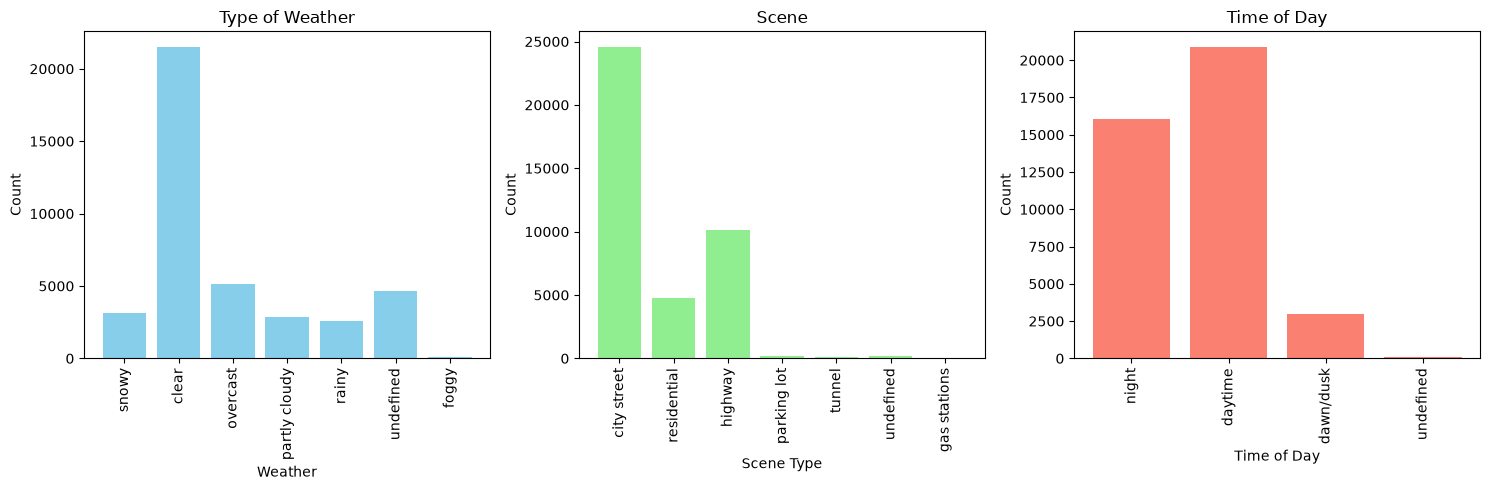

In [52]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))

# 3. Plot the first Counter object on 'ax1'
ax1.bar(list(weather_count.keys()), list(weather_count.values()), color='skyblue')
ax1.set_title("Type of Weather")
ax1.set_xlabel("Weather")
ax1.set_ylabel("Count")
ax1.tick_params(axis='x', rotation=90)

# 4. Plot the second Counter object on 'ax2'
ax2.bar(list(scene_count.keys()), list(scene_count.values()), color='lightgreen')
ax2.set_title("Scene")
ax2.set_xlabel("Scene Type")
ax2.set_ylabel("Count")
ax2.tick_params(axis='x', rotation=90)

# 5. Plot the third Counter object on 'ax3'
ax3.bar(list(timeofday_count.keys()), list(timeofday_count.values()), color='salmon')
ax3.set_title("Time of Day")
ax3.set_xlabel("Time of Day")
ax3.set_ylabel("Count")
ax3.tick_params(axis='x', rotation=90)

# 6. Automatically adjust layout so labels and titles don't overlap
plt.tight_layout()

# 7. Display the side-by-side plots
plt.show()


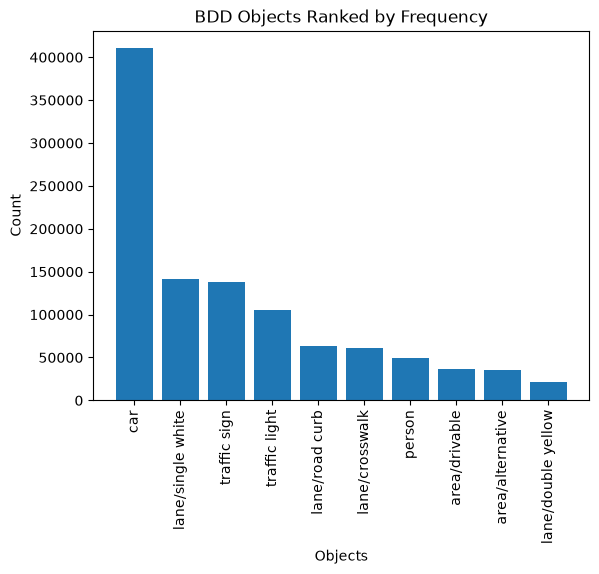

In [42]:
labels, values = zip(*category_count.most_common(10))

plt.bar(labels, values)

plt.xticks(rotation=90)
plt.xlabel("Objects")
plt.ylabel("Count")
plt.title("BDD Objects Ranked by Frequency")
plt.show()